In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
%config InlineBackend.figure_formats = ["retina"]

import json
import math
import sys

import matplotlib.pyplot as plt
import numpy as np
sys.path.insert(0, "../../../skills/academic-figure/assets")  # the skill's style files
import paper  # registers the bundled Inter font
from paper import fit_height, mark_value, smooth, darken, lighten, text_color

colors = paper.use_design("../../../skills/academic-figure/assets/DESIGN.md")  # the style from DESIGN.md's tokens; colors["series-1"], colors["ours"], …

## reward-distribution

**Figure 4: Reward-model scores of responses from three policies.** Violins show the kernel density of the scores of 400 responses per policy; inside, the bar spans the quartiles, the thin line reaches 1.5× the interquartile range, and the white dot marks the median. Scores split into a low and a high mode, and our policy moves 91% of responses above 0.5, into the high mode, against 59% for PPO and 40% for SFT.

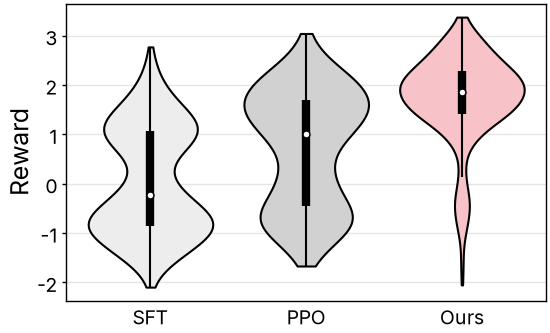

In [2]:
from matplotlib import rcParams

with open("../data/reward-distribution.json") as f:
    rewards = json.load(f)["rewards"]

policies = [("SFT", lighten(colors["neutral"])), ("PPO", colors["neutral"]), ("Ours", colors["ours"])]

fig, ax = plt.subplots(figsize=(2.75, 2))
for x, (policy, color) in enumerate(policies):
    values = rewards[policy]
    parts = ax.violinplot(values, positions=[x], widths=0.8, showextrema=False)
    body = parts["bodies"][0]
    body.set_facecolor(lighten(color))
    body.set_edgecolor("black")
    body.set_linewidth(0.75)
    body.set_alpha(1)

    q1, median, q3 = np.percentile(values, [25, 50, 75])
    low = min(v for v in values if v >= q1 - 1.5 * (q3 - q1))
    high = max(v for v in values if v <= q3 + 1.5 * (q3 - q1))
    ax.vlines(x, low, high, color=colors["ink"], linewidth=rcParams["patch.linewidth"])
    ax.vlines(x, q1, q3, color=colors["ink"], linewidth=4 * rcParams["patch.linewidth"])
    ax.plot(x, median, "o", color=colors["ink"], markerfacecolor="white", zorder=3)

ax.set_xticks(range(len(policies)), labels=[policy for policy, _ in policies])
ax.tick_params(axis="x", length=0)
ax.grid(axis="x", visible=False)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:g}")
ax.set_ylabel("Reward")

fit_height(fig, ax, aspect=0.618)
fig.savefig("../outputs/reward-distribution.pdf")
fig.savefig("../outputs/reward-distribution.png")
plt.show()